In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score, roc_curve

In [2]:
df = pd.concat([pd.read_csv('../data/raw/customer_churn_dataset-testing-master.csv'), pd.read_csv('../data/raw/customer_churn_dataset-training-master.csv')])
df.rename(columns=lambda x: x.lower().replace(' ', '_'), inplace=True)
df

,customerid,age,gender,tenure,usage_frequency,support_calls,payment_delay,subscription_type,contract_length,total_spend,last_interaction,churn
0,1.0,22.0,Female,25.0,14.0,4.0,27.0,Basic,Monthly,598.00,9.0,1.0
1,2.0,41.0,Female,28.0,28.0,7.0,13.0,Standard,Monthly,584.00,20.0,0.0
2,3.0,47.0,Male,27.0,10.0,2.0,29.0,Premium,Annual,757.00,21.0,0.0
3,4.0,35.0,Male,9.0,12.0,5.0,17.0,Premium,Quarterly,232.00,18.0,0.0
4,5.0,53.0,Female,58.0,24.0,9.0,2.0,Standard,Annual,533.00,18.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
440828,449995.0,42.0,Male,54.0,15.0,1.0,3.0,Premium,Annual,716.38,8.0,0.0
440829,449996.0,25.0,Female,8.0,13.0,1.0,20.0,Premium,Annual,745.38,2.0,0.0
440830,449997.0,26.0,Male,35.0,27.0,1.0,5.0,Standard,Quarterly,977.31,9.0,0.0
440831,449998.0,28.0,Male,55.0,14.0,2.0,0.0,Standard,Quarterly,602.55,2.0,0.0


In [228]:
df.dropna(inplace=True)

In [229]:
y = df['churn']
X = df.drop('churn', axis=1)

In [230]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [231]:
X_train.shape, X_test.shape

((404164, 11), (101042, 11))

In [232]:
X_train['con_len_enc'] = X_train['contract_length'].apply(lambda x: 1 if x == 'Monthly' else 3 if x == 'Quarterly' else 12)
X_test['con_len_enc'] = X_test['contract_length'].apply(lambda x: 1 if x == 'Monthly' else 3 if x == 'Quarterly' else 12)

X_train['gender_enc'] = X_train['gender'].apply(lambda x: 1 if x == 'Male' else 0)
X_test['gender_enc'] = X_test['gender'].apply(lambda x: 1 if x == 'Male' else 0)

X_train['sub_type_enc'] = X_train['subscription_type'].apply(lambda x: 0 if x == 'Basic' else 1 if x == 'Standard' else 2)
X_test['sub_type_enc'] = X_test['subscription_type'].apply(lambda x: 0 if x == 'Basic' else 1 if x == 'Standard' else 2)

In [233]:
"""
#THIS WAY OF ENCODING COULD HAVE BEEN USED TOO

sub_cat = ['Basic', 'Standard', 'Premium']
con_len_cat = ['Monthly','Quarterly','Annual']

X_train_other = []
X_test_other = []

#splitting categorical features from numerical
X_train_other = X_train[['subscription_type', 'contract_length']]
X_test_other = X_test[['subscription_type', 'contract_length']]


ordinal = OrdinalEncoder(categories=[sub_cat, con_len_cat])
encoder_lbl = LabelEncoder()

#ordinal encoding
X_train_other_enc = ordinal.fit_transform(X_train_other)
X_test_other_enc = ordinal.fit_transform(X_test_other)

#simple label encoding since gender has no specific order OneHotEncoder could have been used too
X_train['gender_enc'] = encoder_lbl.fit_transform(X_train['gender'])
X_test['gender_enc'] = encoder_lbl.fit_transform(X_test['gender'])

#converting them to dataframe to concatenate them with all the other features
X_train_other_enc_df = pd.DataFrame(X_train_other_enc, columns=X_train_other.columns)
X_test_other_enc_df = pd.DataFrame(X_test_other_enc, columns=X_test_other.columns)

#now concatinating the encoded features with all the features
X_train[['sub_type_enc', 'con_len_enc']] = X_train_other_enc_df[['subscription_type','contract_length']]
X_test[['sub_type_enc', 'con_len_enc']] = X_test_other_enc_df[['subscription_type','contract_length']]


X_train, X_test

"""

"\n#THIS WAY OF ENCODING COULD HAVE BEEN USED TOO\n\nsub_cat = ['Basic', 'Standard', 'Premium']\ncon_len_cat = ['Monthly','Quarterly','Annual']\n\nX_train_other = []\nX_test_other = []\n\n#splitting categorical features from numerical\nX_train_other = X_train[['subscription_type', 'contract_length']]\nX_test_other = X_test[['subscription_type', 'contract_length']]\n\n\nordinal = OrdinalEncoder(categories=[sub_cat, con_len_cat])\nencoder_lbl = LabelEncoder()\n\n#ordinal encoding\nX_train_other_enc = ordinal.fit_transform(X_train_other)\nX_test_other_enc = ordinal.fit_transform(X_test_other)\n\n#simple label encoding since gender has no specific order OneHotEncoder could have been used too\nX_train['gender_enc'] = encoder_lbl.fit_transform(X_train['gender'])\nX_test['gender_enc'] = encoder_lbl.fit_transform(X_test['gender'])\n\n#converting them to dataframe to concatenate them with all the other features\nX_train_other_enc_df = pd.DataFrame(X_train_other_enc, columns=X_train_other.column

In [234]:
X_train.drop(columns=['customerid', 'gender', 'subscription_type', 'contract_length'], inplace=True)
X_test.drop(columns=['customerid', 'gender', 'subscription_type', 'contract_length'], inplace=True)

In [235]:
X_train, X_test

(         age  tenure  usage_frequency  support_calls  payment_delay  \
 64010   55.0    35.0             26.0            7.0            3.0   
 360884  36.0    26.0             15.0            3.0           20.0   
 389297  42.0    58.0             18.0            2.0            0.0   
 41660   62.0    31.0             26.0            6.0           10.0   
 76518   19.0    46.0             28.0            4.0           18.0   
 ...      ...     ...              ...            ...            ...   
 69671   48.0    37.0             10.0            6.0            4.0   
 236046  35.0     3.0             24.0            5.0           29.0   
 82729   58.0    24.0              2.0            2.0            0.0   
 329565  44.0     6.0             14.0            3.0           14.0   
 374589  33.0    31.0             14.0            2.0           19.0   
 
         total_spend  last_interaction  con_len_enc  gender_enc  sub_type_enc  
 64010        587.00               3.0            1   

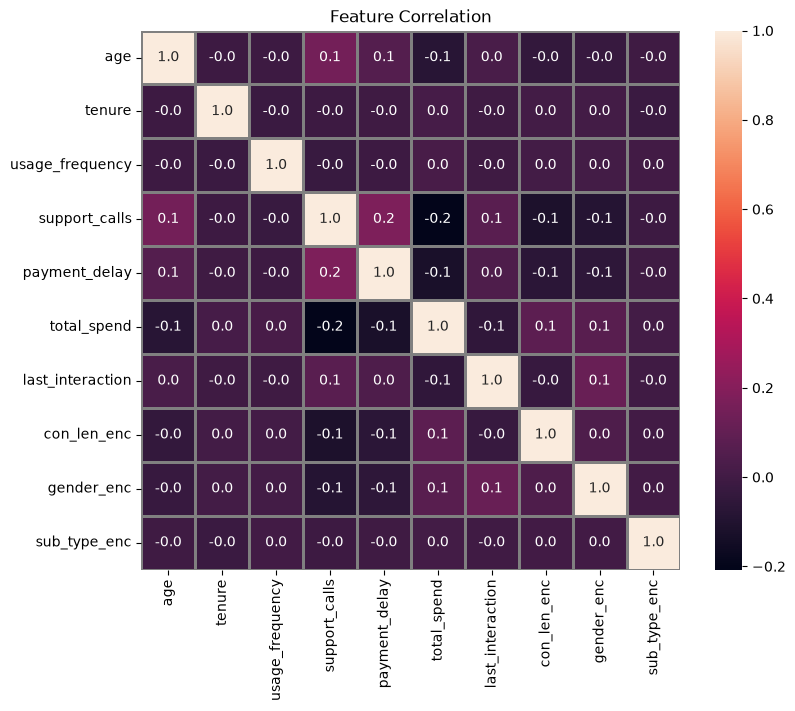

In [236]:
plt.figure(figsize=(9, 7))
plt.title('Feature Correlation')

sns.heatmap(X_train.corr(), 
            annot=True, 
            square=True, 
            fmt='.1f',
            linewidths=1, 
            linecolor='gray')
plt.show()

there seem to be some correlation between support calls and total spend, but it can be ignored for now

In [237]:
#converting the features from float to int to decrease their size
X_train[['age','tenure','usage_frequency', 'support_calls','payment_delay','last_interaction','gender_enc','sub_type_enc','con_len_enc']] = X_train[['age','tenure','usage_frequency', 'support_calls','payment_delay','last_interaction','gender_enc','sub_type_enc','con_len_enc']].astype('int8')
X_train['total_spend'] = X_train['total_spend'].astype('int16')

X_test[['age','tenure','usage_frequency', 'support_calls','payment_delay','last_interaction','gender_enc','sub_type_enc','con_len_enc']] = X_test[['age','tenure','usage_frequency', 'support_calls','payment_delay','last_interaction','gender_enc','sub_type_enc','con_len_enc']].astype('int8')
X_test['total_spend'] = X_test['total_spend'].astype('int16')

y_train = y_train.astype('int8')
y_test = y_test.astype('int8')

X_train.info(), X_test.info(), y_train.info(), y_test.info()

<class 'pandas.DataFrame'>
Index: 404164 entries, 64010 to 374589
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   age               404164 non-null  int8 
 1   tenure            404164 non-null  int8 
 2   usage_frequency   404164 non-null  int8 
 3   support_calls     404164 non-null  int8 
 4   payment_delay     404164 non-null  int8 
 5   total_spend       404164 non-null  int16
 6   last_interaction  404164 non-null  int8 
 7   con_len_enc       404164 non-null  int8 
 8   gender_enc        404164 non-null  int8 
 9   sub_type_enc      404164 non-null  int8 
dtypes: int16(1), int8(9)
memory usage: 7.3 MB
<class 'pandas.DataFrame'>
Index: 101042 entries, 142013 to 45069
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   age               101042 non-null  int8 
 1   tenure            101042 non-null  int8 
 2   usage_frequenc

(None, None, None, None)

In [238]:
X_train.describe(), X_test.describe(), y_train.describe(), y_test.describe()

(                 age         tenure  usage_frequency  support_calls  \
 count  404164.000000  404164.000000    404164.000000  404164.000000   
 mean       39.700923      31.336307        15.716392       3.832674   
 std        12.669015      17.230966         8.621737       3.133145   
 min        18.000000       1.000000         1.000000       0.000000   
 25%        29.000000      16.000000         8.000000       1.000000   
 50%        40.000000      32.000000        16.000000       3.000000   
 75%        49.000000      46.000000        23.000000       6.000000   
 max        65.000000      60.000000        30.000000      10.000000   
 
        payment_delay    total_spend  last_interaction    con_len_enc  \
 count  404164.000000  404164.000000     404164.000000  404164.000000   
 mean       13.487503     619.935801         14.599343       6.103319   
 std         8.448652     245.317618          8.606493       4.802074   
 min         0.000000     100.000000          1.000000    

In [240]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
x_test_std = scaler.fit_transform(X_test)


In [ ]:
dummy = DummyClassifier(random_state=42)
LR = LogisticRegression(random_state=42)
RFC = RandomForestClassifier(random_state=42)
DTC = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
KNC = KNeighborsClassifier(n_neighbors=5,metric="minkowski",p=2,n_jobs=1)
XGB = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1, 
    objective='binary:logistic',
    random_state=42
)

In [242]:
dummy.fit(X_train_std, y_train)
LR.fit(X_train_std, y_train)
RFC.fit(X_train, y_train)
DTC.fit(X_train, y_train)
KNC.fit(X_train_std, y_train)
XGB.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [243]:
from sklearn.metrics import precision_score, recall_score


models = {
    "Dummy Classifier": dummy,
    "Logistic Regression":LR,
    "RandomForestClassifier":RFC,
    "DecisionTreeClassifier":DTC,
    "KNearestNeighbor": KNC,
    "XGBClassifier": XGB
}

scores = {}

for name, model in models.items():
    if model == "RandomForestClassifier" or model == "XGBClassifier" or model == "DecisionTreeClassifier":
        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)[:,1]
    else:
        predictions = model.predict(x_test_std)
        probabilities = model.predict_proba(x_test_std)[:,1]

    
    scores[name] = {
        "Accuracy":accuracy_score(y_test, predictions),
        "Precision":precision_score(y_test, predictions),
        "Recall":recall_score(y_test, predictions),
        "F1":f1_score(y_test, predictions),
        "ROC AUC":roc_auc_score(y_test, probabilities)
    }
    
df_results = pd.DataFrame(scores).T
print(df_results)

c:\Users\PC-01\Desktop\Project\customer churn ml\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\PC-01\Desktop\Project\customer churn ml\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


c:\Users\PC-01\Desktop\Project\customer churn ml\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\PC-01\Desktop\Project\customer churn ml\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


                        Accuracy  Precision    Recall        F1   ROC AUC
Dummy Classifier        0.555205   0.555205  1.000000  0.713996  0.500000
Logistic Regression     0.823944   0.848514  0.831316  0.839827  0.891993
RandomForestClassifier  0.555205   0.555205  1.000000  0.713996  0.671179
DecisionTreeClassifier  0.555205   0.555205  1.000000  0.713996  0.500000
KNearestNeighbor        0.884682   0.898807  0.892814  0.895801  0.924214
XGBClassifier           0.555205   0.555205  1.000000  0.713996  0.591024


leaving dummy model behind next we will do some hyperparameter tuning using RandomizedSearch CV as GridSearchCV would consume too much processing power